In [ ]:
!pip install tensorflow matplotlib scikit-learn

# New Section

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image_dataset_from_directory
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Set dataset path (change if different)
dataset_path = '/content/drive/MyDrive/UCOSTProject' # Corrected path

# Load training and validation sets (80/20 split)
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123

train_ds = image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset='training',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset='validation',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
print("Classes:", class_names)

Found 220 files belonging to 2 classes.
Using 176 files for training.
Found 220 files belonging to 2 classes.
Using 44 files for validation.
Classes: ['Sal images', 'deodar images']


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

In [ ]:
model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(2, activation='softmax')  # 2 classes: Quercus, Teak
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/preprocessing/tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,218 (42.61 MB)

 Trainable params: 11,169,218 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10  # Increase if needed
)

Epoch 1/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 63s 7s/step - accuracy: 0.9632 - loss: 0.1087 - val_accuracy: 0.9318 - val_loss: 0.2091
Epoch 2/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 48s 7s/step - accuracy: 0.9853 - loss: 0.0631 - val_accuracy: 0.9318 - val_loss: 0.2355
Epoch 3/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 79s 7s/step - accuracy: 0.9729 - loss: 0.0754 - val_accuracy: 0.8864 - val_loss: 0.3830
Epoch 4/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 51s 8s/step - accuracy: 0.9518 - loss: 0.0828 - val_accuracy: 0.9318 - val_loss: 0.1211
Epoch 5/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 46s 7s/step - accuracy: 1.0000 - loss: 0.0190 - val_accuracy: 0.9545 - val_loss: 0.1140
Epoch 6/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 81s 7s/step - accuracy: 1.0000 - loss: 0.0093 - val_accuracy: 0.9318 - val_loss: 0.1139
Epoch 7/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 46s 7s/step - accuracy: 1.0000 - loss: 0.0045 - val_accuracy: 0.9545 - val_loss: 0.1203
Epoch 8/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 87s 8s/step - accuracy: 1.0000 - loss: 0.0039 - val_accuracy: 0.9773 - val_loss: 0.0878
Epoch 9/

In [ ]:
# Save the trained model in the newer Keras format
model.save('/content/drive/MyDrive/wood_model_deodar_sal.keras')

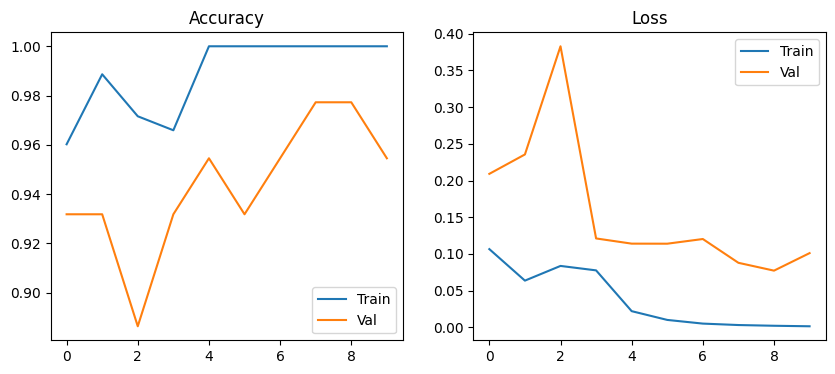

In [ ]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('Loss')
plt.legend()

plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step


<Figure size 600x600 with 0 Axes>

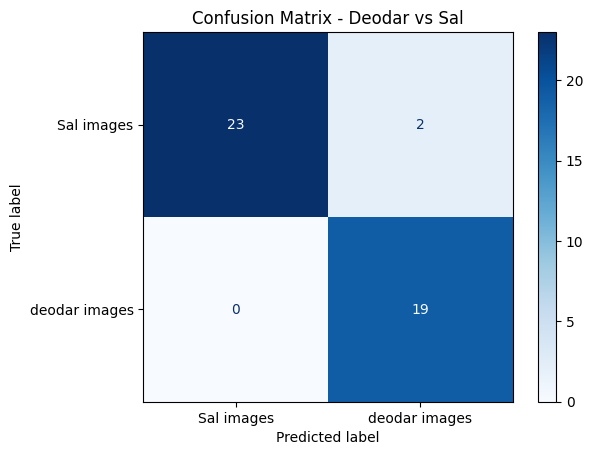

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get all validation images and labels
val_images = []
val_labels = []

for images, labels in val_ds:
    val_images.append(images)
    val_labels.append(labels)

val_images = tf.concat(val_images, axis=0)
val_labels = tf.concat(val_labels, axis=0)

# Predict on all validation images
y_pred_probs = model.predict(val_images)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = val_labels.numpy()

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

# Plot
plt.figure(figsize=(6, 6))
disp.plot(cmap='Blues', values_format='d')
plt.title("Confusion Matrix - Deodar vs Sal")
plt.grid(False)
plt.show()

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

# Print accuracy
accuracy = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {accuracy:.4f}")

# Print precision, recall, F1-score
report = classification_report(y_true, y_pred, target_names=class_names)
print("Classification Report:\n", report)

Test Accuracy: 0.9545
Classification Report:
                precision    recall  f1-score   support

   Sal images       1.00      0.92      0.96        25
deodar images       0.90      1.00      0.95        19

     accuracy                           0.95        44
    macro avg       0.95      0.96      0.95        44
 weighted avg       0.96      0.95      0.95        44



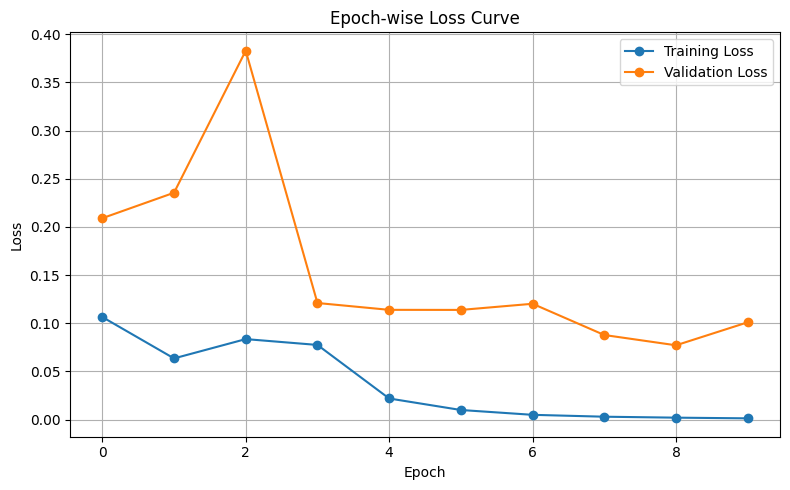

In [ ]:
import matplotlib.pyplot as plt

# Plotting training & validation loss over epochs
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss', marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', marker='o')
plt.title('Epoch-wise Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

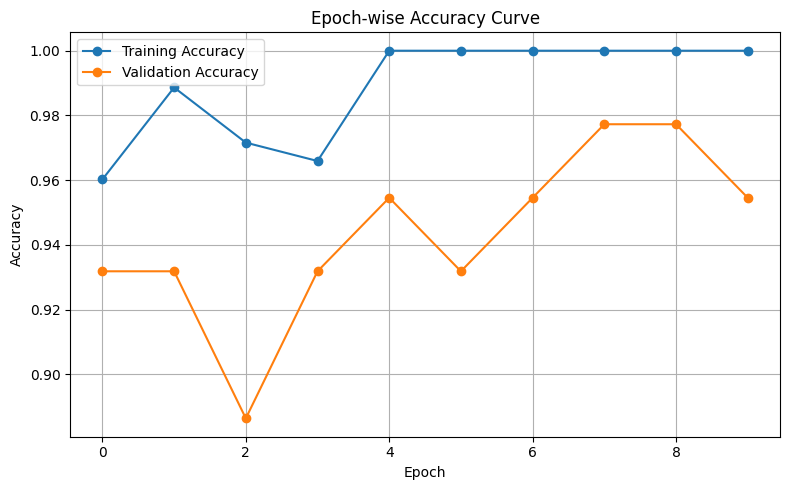

In [ ]:
# Plotting training & validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Epoch-wise Accuracy Curve')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 636ms/step


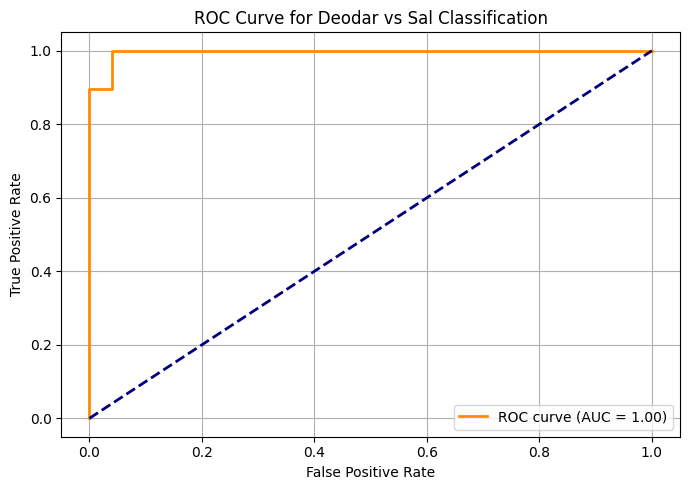

In [ ]:
from sklearn.metrics import roc_curve, auc

# Make sure we have the validation images and labels
# (reusing val_images and val_labels from earlier step)
y_true = val_labels.numpy()

# Get prediction probabilities for the positive class (e.g.,sal)
# Note: model.predict returns probabilities for both classes
y_pred_probs = model.predict(val_images)
y_scores = y_pred_probs[:, 1]  # Probability of class 1 (e.g., 'sal')

# Compute False Positive Rate and True Positive Rate
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Deodar vs Sal Classification')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

Shape of features: (300, 100)
Shape of labels: (300,)
Unique labels: ['Deodar' 'Sal']


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


Shape of t-SNE reduced features: (300, 2)


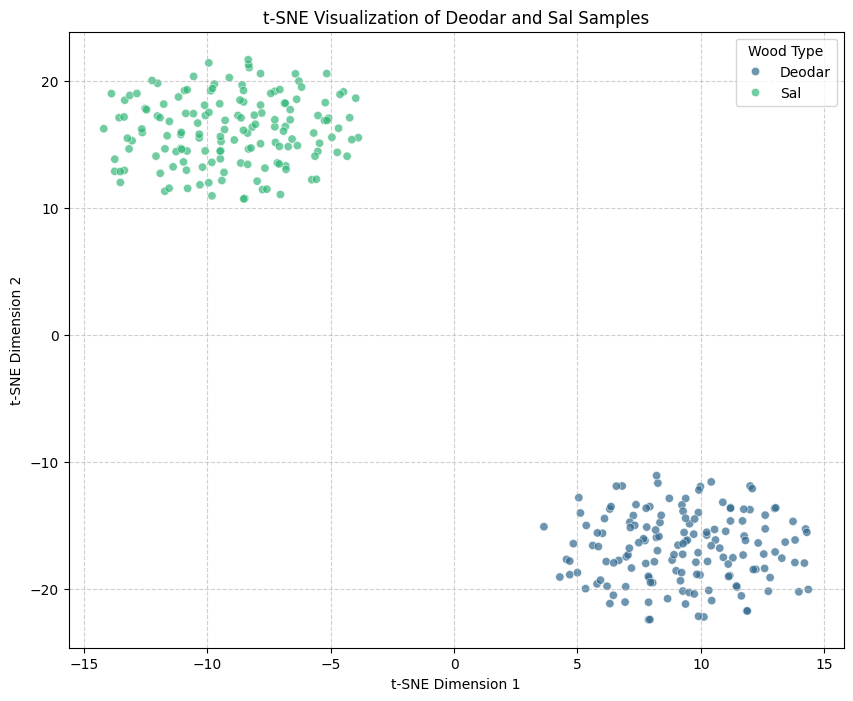

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import pandas as pd
import seaborn as sns

# ---  T-SNE VISUALIZATION ---

# IMPORTANT: REPLACE THIS DUMMY DATA WITH YOUR ACTUAL 'features' AND 'labels'
# For Deodar
num_deodar_samples = 150
deodar_features = np.random.rand(num_deodar_samples, 100) * 5 + 10 # 100 features, slightly different range
deodar_labels = ['Deodar'] * num_deodar_samples

# For Sal
num_sal_samples = 150
sal_features = np.random.rand(num_sal_samples, 100) * 5 + 20 # 100 features, slightly different range
sal_labels = ['Sal'] * num_sal_samples

features = np.vstack((deodar_features, sal_features))
labels = np.array(deodar_labels + sal_labels)

print(f"Shape of features: {features.shape}")
print(f"Shape of labels: {labels.shape}")
print(f"Unique labels: {np.unique(labels)}")

# 1. Initialize and run t-SNE
# perplexity: This parameter relates to the number of nearest neighbors that are considered.
#             It's often recommended to try values between 5 and 50.
# n_components: The dimensionality of the embedded space (usually 2 for 2D visualization).
# learning_rate: Controls the step size during optimization.
# n_iter: Number of iterations to run.
tsne = TSNE(n_components=2, random_state=42, perplexity=30, learning_rate=200, n_iter=1000)
features_2d = tsne.fit_transform(features)

print(f"Shape of t-SNE reduced features: {features_2d.shape}")

# 2. Create a DataFrame for easier plotting with Seaborn
df_tsne = pd.DataFrame(features_2d, columns=['Dimension 1', 'Dimension 2'])
df_tsne['Wood Type'] = labels

# 3. Visualize the t-SNE output
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='Dimension 1', y='Dimension 2',
    hue='Wood Type',
    palette='viridis', # Or 'Set1', 'Dark2', etc. for different color schemes
    data=df_tsne,
    legend='full',
    alpha=0.7 # Transparency of the points
)

plt.title('t-SNE Visualization of Deodar and Sal Samples')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Optional: If you want to save the plot
# plt.savefig('tsne_wood_visualization.png', dpi=300, bbox_inches='tight')
# print("t-SNE plot saved as 'tsne_wood_visualization.png'")

In [ ]:
# Save the trained model in the newer Keras format
model.save('/content/drive/MyDrive/wood_model_quercus_teak.keras')